# SupeRR Selector Season 2 - Round 1: Reliable Players Under Pressure
**End-to-end analysis notebook** (IPL 2022-2026 + full-member T20Is)

Sections
1. Setup and data audit
2. Exploratory analysis (what does T20 data look like?)
3. Cleaning and match-state construction
4. Win-probability model
5. Defining pressure (leverage) and validating it
6. Ball-level performance value
7. Player ratings (hierarchical ridge, baselines, consistency, composite)
8. Final top 10s
9. Robustness: alternative definitions, weights, bootstrap, split-half reliability
10. Extra analysis: model vs naive stats, IPL vs T20I, uplift
11. Export

Pressure = **leverage**: expected absolute change in win probability the next ball can cause. Performance = win probability added over what an average ball would add in the same state, divided by leverage ("efficiency").

## 0. Data-to-dashboard flow (how every number and every dashboard file is produced)
```
ball_by_ball.csv, matches.csv, competitions.csv,        Sections 1-3   clean + build match state (runs, wickets, balls left, target)
competition_team_player_mapping.csv, playing_eleven.csv  Section 4     cross-fitted win-probability (WP) model
        |                                                Section 5     leverage (pressure) + HP label
        v                                                Sections 6-7   ball value -> hierarchical ridge -> composite score -> top 10
   this notebook  ------------------------------------> Section 9-10   robustness, bootstrap, split-half, extra analysis
        |                                                Section 11     rating CSVs (bat_/bowl_ratings_all_eligible.csv)
        v                                                Section 12     the five dashboard JSON files (league_stats, outcome_probs, wp_grid, players, matches)
   dashboard (static viewer of the JSONs)                Section 13     audit cells that re-check the claims made in the report
```
The dashboard contains **no analysis of its own**: it only reads the JSON files written by Section 12, so anybody holding the raw CSVs can regenerate it by running this notebook top to bottom.
Put the five competition CSVs next to the notebook (or edit `DATA_DIR` in the first code cell).

## 1. Setup and data audit

In [1]:
import os, warnings, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.linear_model import Ridge
from sklearn.metrics import brier_score_loss, roc_auc_score
from scipy.stats import spearmanr, pearsonr
pd.set_option('display.width',200); pd.set_option('display.max_columns',40)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'font.size':9})
PINK,NAVY,GREY='#e5097f','#0b1f3a','#9aa5b1'

DATA_DIR='/mnt/user-data/uploads/' if os.path.exists('/mnt/user-data/uploads/ball_by_ball.csv') else './'   # change if needed
OUT_DIR='/mnt/user-data/outputs/' if os.path.exists('/mnt/user-data/outputs') else './'
raw_b=pd.read_csv(DATA_DIR+'ball_by_ball.csv'); raw_m=pd.read_csv(DATA_DIR+'matches.csv'); comps=pd.read_csv(DATA_DIR+'competitions.csv')
players=pd.read_csv(DATA_DIR+'competition_team_player_mapping.csv'); xi=pd.read_csv(DATA_DIR+'playing_eleven.csv')
raw_m=raw_m.merge(comps,on='comp_id')
print('ball_by_ball',raw_b.shape,'| matches',raw_m.shape,'| playing XI',xi.shape,'| comp-team-player',players.shape)
print('matches with ball data:',raw_b.match_id.nunique(),'| date range',raw_m.match_date.min(),'to',raw_m.match_date.max())
print(raw_m.groupby('match_format').size().rename('matches'))
miss=raw_b.isna().mean(); print('\nColumns with missing values:'); print(miss[miss>0].round(3))

ball_by_ball (200999, 33) | matches (883, 25) | playing XI (28381, 9) | comp-team-player (6413, 6)
matches with ball data: 867 | date range 2022-01-22 to 2026-11-01
match_format
T20     401
T20I    482
Name: matches, dtype: int64

Columns with missing values:
dismissal_type_id      0.946
dismissal_type         0.946
dismissed_player_id    0.946
extras_type            0.941
stroke                 0.031
delivery_style         0.002
over_or_around         0.002
dtype: float64


**Decoding the ball file.** Runs off the bat are in `runs`; extras in `extras1_runs`/`extras_2_runs`. The checks below establish which `extras_type` values are non-legal deliveries.

In [2]:
raw_b['tot']=raw_b.runs+raw_b.extras1_runs+raw_b.extras_2_runs
print(raw_b.groupby('extras_type')[['runs','extras1_runs','extras_2_runs','tot']].mean().round(2))
b1=raw_b[raw_b.innings<=2]
for name,ill in [('wide+Overstep',['wide','Overstep']),('wide+Overstep+other',['wide','Overstep','other'])]:
    g=b1.assign(l=~b1.extras_type.isin(ill)).groupby(['match_id','innings','overid']).l.sum()
    print(f'{name:22s} share of overs with exactly 6 legal balls: {(g==6).mean():.3f}')
print('=> wides and no-balls (Overstep / other) are NOT legal deliveries')
print(raw_b.dismissal_type.value_counts())

             runs  extras1_runs  extras_2_runs   tot
extras_type                                         
Overstep     1.48          1.00           0.08  2.56
Penalty      0.00          5.00           0.00  5.00
byes         0.00          1.89           0.00  1.89
legbyes      0.00          1.31           0.00  1.31
other        1.56          1.00           0.13  2.69
wide         0.00          1.19           0.00  1.19
wide+Overstep          share of overs with exactly 6 legal balls: 0.975
wide+Overstep+other    share of overs with exactly 6 legal balls: 0.982
=> wides and no-balls (Overstep / other) are NOT legal deliveries
dismissal_type
Caught                   7557
Bowled                   1775
LBW                       709
RunOut                    600
Stump                     214
Hit Wicket                 17
Retire Out                  6
Obstracting the field       2
Obstructing the field       1
Name: count, dtype: int64


## 2. Exploratory analysis

In [3]:
# Match filter (IPL + full-member T20I, completed, no DLS/revised target)
full={'India','Pakistan','West Indies','New Zealand','Bangladesh','England','Sri Lanka','Australia','South Africa','Zimbabwe','Afghanistan','Ireland'}
ipl=raw_m.comp_name.str.startswith('IPL')
t20i=(raw_m.match_format=='T20I')&raw_m.home_team.isin(full)&raw_m.away_team.isin(full)
ok=(ipl|t20i)&raw_m.revised_target.isna()&raw_m.first_inn_revised_overs.isna()&raw_m.second_inn_revised_overs.isna()
ok&=~raw_m.result.fillna('').str.contains('Tied|No Result|Abandoned|DLS|D/L',case=False)&raw_m.win_team_id.notna()
mm=raw_m[ok].copy(); mm['is_ipl']=ipl[ok].astype(int)
funnel=pd.Series({'matches in file':len(raw_m),'with ball-by-ball':raw_m.match_id.isin(raw_b.match_id).sum(),'IPL or T20I (any teams)':((raw_m.match_format=='T20I')|ipl).sum(),
  'IPL or full-member T20I':(ipl|t20i).sum(),'+ completed, no DLS/tie':ok.sum()}); print(funnel)
print(mm.groupby('is_ipl').size().rename({0:'T20I',1:'IPL'}))

matches in file            883
with ball-by-ball          867
IPL or T20I (any teams)    853
IPL or full-member T20I    799
+ completed, no DLS/tie    730
dtype: int64
is_ipl
T20I    376
IPL     354
dtype: int64


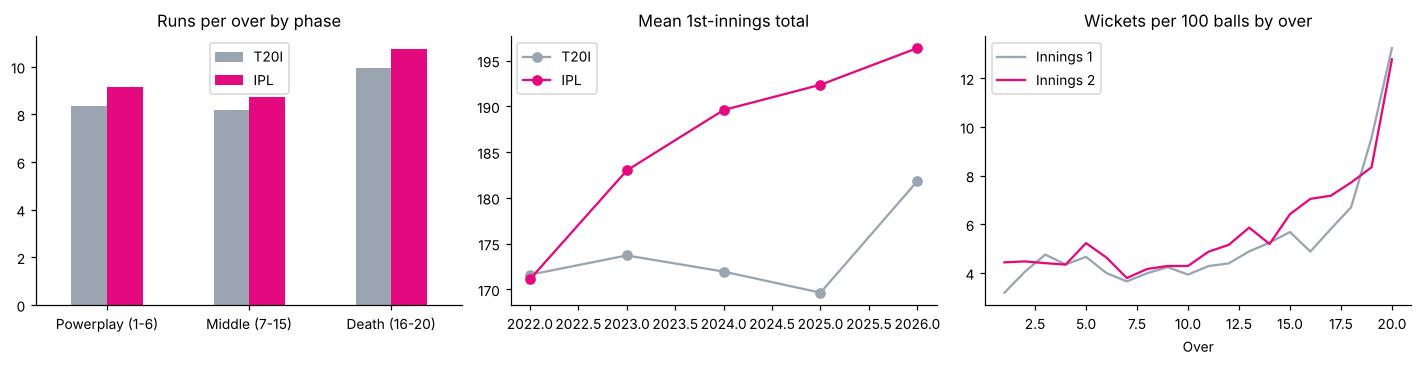

Batting-first win rate: IPL 0.477 | T20I 0.503
Toss winner won the match: 0.512


In [4]:
eb=raw_b[raw_b.match_id.isin(mm.match_id)&raw_b.innings.isin([1,2])].merge(mm[['match_id','is_ipl','match_date','comp_name','win_team_id']],on='match_id')
eb['legal']=~eb.extras_type.isin(['wide','Overstep','other','Penalty']); eb['season']=pd.to_datetime(eb.match_date).dt.year
eb['phase']=pd.cut(eb.overid,[0,6,15,20],labels=['Powerplay (1-6)','Middle (7-15)','Death (16-20)'])
fig,ax=plt.subplots(1,3,figsize=(13,3.4))
# scoring rate by phase, competition type
rr=eb.groupby(['phase','is_ipl']).apply(lambda x:x.tot.sum()/x.legal.sum()*6).unstack(); rr.columns=['T20I','IPL']; rr.plot.bar(ax=ax[0],color=[GREY,PINK],rot=0); ax[0].set_title('Runs per over by phase'); ax[0].set_xlabel('')
# first-innings totals by season
tot1=eb[eb.innings==1].groupby(['match_id','season','is_ipl']).tot.sum().reset_index(); tt=tot1.groupby(['season','is_ipl']).tot.mean().unstack(); tt.columns=['T20I','IPL']; tt.plot(ax=ax[1],marker='o',color=[GREY,PINK]); ax[1].set_title('Mean 1st-innings total'); ax[1].set_xlabel('')
# wicket rate by over
w=eb.groupby(['overid','innings']).is_wicket.mean().unstack(); w.columns=['Innings 1','Innings 2']; (w*100).plot(ax=ax[2],color=[GREY,PINK]); ax[2].set_title('Wickets per 100 balls by over'); ax[2].set_xlabel('Over')
plt.tight_layout(); plt.show()
# chasing success, toss
res=eb.groupby('match_id').agg(w=('win_team_id','first'),bat2=('batting_team_id',lambda s:np.nan)).w
m2=mm.copy(); m2['bat1']=m2.match_id.map(eb[eb.innings==1].groupby('match_id').batting_team_id.first()); m2['bat_first_won']=(m2.win_team_id==m2.bat1)
print('Batting-first win rate: IPL %.3f | T20I %.3f'%tuple(m2.groupby('is_ipl').bat_first_won.mean().loc[[1,0]]))
print('Toss winner won the match: %.3f'%(m2.toss_win_team_id==m2.win_team_id).mean())

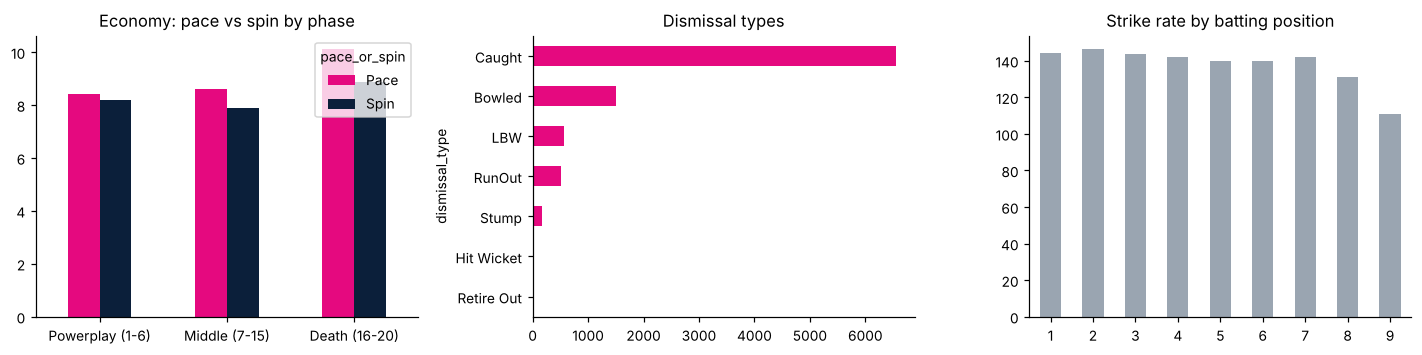

In [5]:
fig,ax=plt.subplots(1,3,figsize=(13,3.3))
d=eb[eb.legal&eb.extras_type.isna()]   # 'None' is read as NaN by pandas
d.groupby(['phase','pace_or_spin']).apply(lambda x:x.tot.mean()*6).unstack().plot.bar(ax=ax[0],color=[PINK,NAVY],rot=0); ax[0].set_title('Economy: pace vs spin by phase'); ax[0].set_xlabel('')
eb[eb.is_wicket].dismissal_type.value_counts().head(7).plot.barh(ax=ax[1],color=PINK); ax[1].set_title('Dismissal types'); ax[1].invert_yaxis()
sr=eb[eb.legal].groupby('batting_order').apply(lambda x:x.runs.sum()/len(x)*100); sr.loc[1:9].plot.bar(ax=ax[2],color=GREY,rot=0); ax[2].set_title('Strike rate by batting position'); ax[2].set_xlabel('')
plt.tight_layout(); plt.show()

## 3. Cleaning and match-state construction

In [6]:
b=eb.drop(columns=['phase','season']).copy()
ni=b.groupby('match_id').innings.nunique(); b=b[b.match_id.isin(ni[ni==2].index)]
b=b.sort_values(['match_id','innings','innings_ball_num']).reset_index(drop=True)
g=b.groupby(['match_id','innings'])
b['runs_b']=g.tot.cumsum()-b.tot; b['balls_b']=g.legal.cumsum()-b.legal.astype(int); b['wk_b']=g.is_wicket.cumsum()-b.is_wicket.astype(int)
b=b.merge(b[b.innings==1].groupby('match_id').tot.sum().rename('inn1_total'),on='match_id'); b['target']=b.inn1_total+1
b=b.merge(b[b.innings==1].groupby('match_id').batting_team_id.first().rename('bat1'),on='match_id')
b['y']=np.where(b.innings==1,b.win_team_id==b.bat1,b.win_team_id!=b.bat1).astype(int)   # batting side eventually wins
b['balls_left']=120-b.balls_b; b['need']=b.target-b.runs_b
b=b[(b.balls_left>0)&(b.wk_b<10)].copy()
print('balls kept:',len(b),'| matches:',b.match_id.nunique(),'| IPL',b[b.is_ipl==1].match_id.nunique(),'T20I',b[b.is_ipl==0].match_id.nunique())
b[['match_id','innings','overid','runs_b','wk_b','balls_left','need','y']].head()

balls kept: 174674 | matches: 730 | IPL 354 T20I 376


,match_id,innings,overid,runs_b,wk_b,balls_left,need,y
0,13511,1,1,0,0,120,104,0
1,13511,1,1,0,0,119,104,0
2,13511,1,1,0,0,118,104,0
3,13511,1,1,0,0,117,104,0
4,13511,1,1,0,0,116,104,0


## 4. Win-probability model (5-fold cross-fitted by match)

Innings 1: out-of-fold Brier 0.2224 (coin flip 0.25) | AUC 0.690
Innings 2: out-of-fold Brier 0.1288 (coin flip 0.25) | AUC 0.899


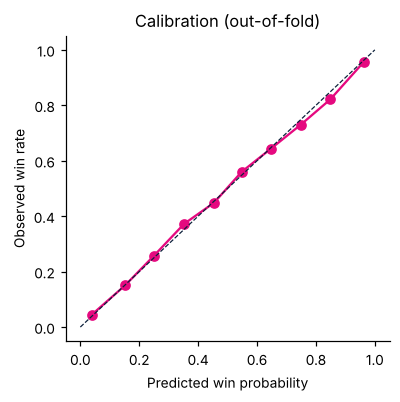

In [7]:
def feats(inn,runs,bl,wk,need,ipl): return np.c_[runs,bl,wk,ipl] if inn==1 else np.c_[need,bl,wk,ipl]
mono={1:[1,1,-1,0],2:[-1,1,-1,0]}
mk=lambda inn:HGB(max_iter=250,learning_rate=0.06,max_depth=4,min_samples_leaf=300,l2_regularization=5,monotonic_cst=mono[inn],random_state=0)
last1=b[b.innings==1].groupby('match_id').tail(1)
term=pd.DataFrame({'match_id':last1.match_id,'runs':last1.runs_b+last1.tot,'bl':120-(last1.balls_b+last1.legal.astype(int)),'wk':last1.wk_b+last1.is_wicket.astype(int),'ipl':last1.is_ipl,'y':last1.y})
mids=b.match_id.unique(); fold=dict(zip(mids,np.random.RandomState(1).randint(0,5,len(mids))))
b['fold']=b.match_id.map(fold); term['fold']=term.match_id.map(fold)
models={}
for f in range(5):
    for inn in (1,2):
        tr=b[(b.innings==inn)&(b.fold!=f)]; X=feats(inn,tr.runs_b,tr.balls_left,tr.wk_b,tr.need,tr.is_ipl); y=tr.y.values
        if inn==1: tt=term[term.fold!=f]; X=np.r_[X,np.c_[tt.runs,tt.bl,tt.wk,tt.ipl]]; y=np.r_[y,tt.y.values]
        models[(f,inn)]=mk(inn).fit(X,y)
def WP(inn,runs,balls,wk,target,ipl,fl):
    out=np.zeros(len(runs))
    for f in range(5):
        for i in (1,2):
            idx=np.where((fl==f)&(inn==i))[0]
            if len(idx)==0: continue
            bl=120-balls[idx]
            X=np.c_[runs[idx],bl,wk[idx],ipl[idx]] if i==1 else np.c_[target[idx]-runs[idx],bl,wk[idx],ipl[idx]]
            p=models[(f,i)].predict_proba(X)[:,1]
            if i==2: p=np.where(runs[idx]>=target[idx],1.0,np.where((bl<=0)|(wk[idx]>=10),0.0,p))
            out[idx]=p
    return out
inn,fl,tg,ipl_=b.innings.values,b.fold.values,b.target.values,b.is_ipl.values
r0,k0,w0=b.runs_b.values,b.balls_b.values,b.wk_b.values
b['wp0']=WP(inn,r0,k0,w0,tg,ipl_,fl)
for i in (1,2):
    s=b[b.innings==i]; print(f'Innings {i}: out-of-fold Brier {brier_score_loss(s.y,s.wp0):.4f} (coin flip 0.25) | AUC {roc_auc_score(s.y,s.wp0):.3f}')
cal=b.groupby(pd.cut(b.wp0,np.linspace(0,1,11))).agg(pred=('wp0','mean'),obs=('y','mean'),n=('y','size'))
plt.figure(figsize=(3.8,3.6)); plt.plot(cal.pred,cal.obs,'o-',color=PINK); plt.plot([0,1],[0,1],'--',color=NAVY,lw=.8); plt.xlabel('Predicted win probability'); plt.ylabel('Observed win rate'); plt.title('Calibration (out-of-fold)'); plt.show()

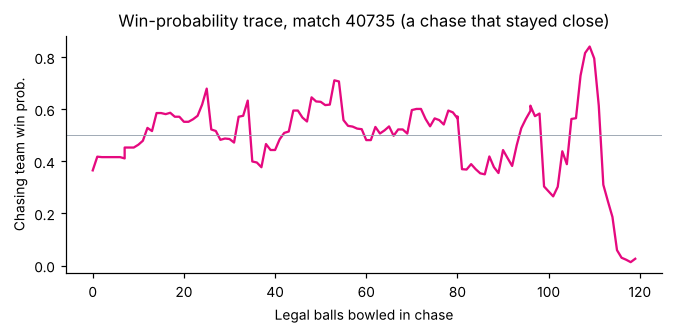

In [8]:
# Example match: win-probability trace of the closest chase in the data (by final-over WP swings)
ex=b[b.innings==2].groupby('match_id').wp0.apply(lambda s:(s.sub(.5).abs()<0.2).mean()).sort_values(ascending=False).index[0]
e=b[(b.match_id==ex)&(b.innings==2)]
plt.figure(figsize=(7,2.8)); plt.plot(e.balls_b,e.wp0,color=PINK); plt.axhline(.5,color=GREY,lw=.6); plt.xlabel('Legal balls bowled in chase'); plt.ylabel('Chasing team win prob.'); plt.title(f'Win-probability trace, match {ex} (a chase that stayed close)'); plt.show()

## 5. Defining pressure: leverage

For every ball we compute the win probability after each possible outcome (0,1,2,3,4,6, wicket, wide), weight by the league outcome probability for that over and competition type, and take
`LI = sum p(outcome) * |WP(outcome) - WP(now)|`.
A ball is **high-pressure (HP)** if LI is in the top 25% of all balls.

In [9]:
cls=[0,1,2,3,4,6]
H=np.zeros((len(b),8))
for j,r in enumerate(cls): H[:,j]=WP(inn,r0+r,k0+1,w0,tg,ipl_,fl)
H[:,6]=WP(inn,r0,k0+1,w0+1,tg,ipl_,fl)          # wicket
H[:,7]=WP(inn,r0+1,k0,w0,tg,ipl_,fl)            # wide (no ball consumed)
cmap=lambda r:np.select([r<=0,r==1,r==2,r==3,r<=5,r>=6],[0,1,2,3,4,5],0)
bowl_w=b.dismissal_type.isin(['Caught','Bowled','LBW','Stump','Hit Wicket'])
bat_w=b.is_wicket&(b.dismissed_player_id==b.striker_id)&(b.dismissal_type!='Retire Out')
isw=b.extras_type=='wide'; isnb=b.extras_type.isin(['Overstep','other'])
b['bat_cls']=np.where(bat_w,6,cmap(b.runs.values)); b['bat_ok']=~isw&(b.extras_type!='Penalty')
b['bowl_cls']=np.where(bowl_w,6,np.where(isw,7,cmap((b.runs+np.where(isnb,b.extras1_runs,0)).values))); b['bowl_ok']=b.extras_type!='Penalty'
def probs(cl,ok,n):
    d=pd.DataFrame({'k':b.is_ipl*100+b.overid,'c':cl})[ok]; t=pd.crosstab(d.k,d.c).reindex(columns=range(n),fill_value=0); return t.div(t.sum(1),axis=0)
key=(b.is_ipl*100+b.overid).values
PB=probs(b.bat_cls,b.bat_ok,7).loc[key].values; PW=probs(b.bowl_cls,b.bowl_ok,8).loc[key].values
wp0=b.wp0.values; ar=np.arange(len(b))
Eb=(PB*H[:,:7]).sum(1)-wp0; Ew=(PW*H).sum(1)-wp0
b['v_bat']=np.where(b.bat_ok,H[ar,np.minimum(b.bat_cls.values,6)]-wp0-Eb,np.nan)        # WP added over expectation, batting view
b['v_bowl']=np.where(b.bowl_ok,-(H[ar,b.bowl_cls.values]-wp0-Ew),np.nan)                   # bowling view
b['LI']=(PW*np.abs(H-wp0[:,None])).sum(1)
THR=b.LI.quantile(.75); CAP=b.LI.quantile(.99); b['HP']=b.LI>=THR; b['w']=np.minimum(b.LI,CAP)
print(f'HP threshold (P75) = {THR:.4f} | weight cap (P99) = {CAP:.4f} | HP balls = {b.HP.sum():,} ({b.HP.mean():.0%})')
print('Mean v_bat %.5f, mean v_bowl %.5f (should be ~0)'%(b.v_bat.mean(),b.v_bowl.mean()))

HP threshold (P75) = 0.0199 | weight cap (P99) = 0.0746 | HP balls = 43,669 (25%)
Mean v_bat 0.00001, mean v_bowl -0.00003 (should be ~0)


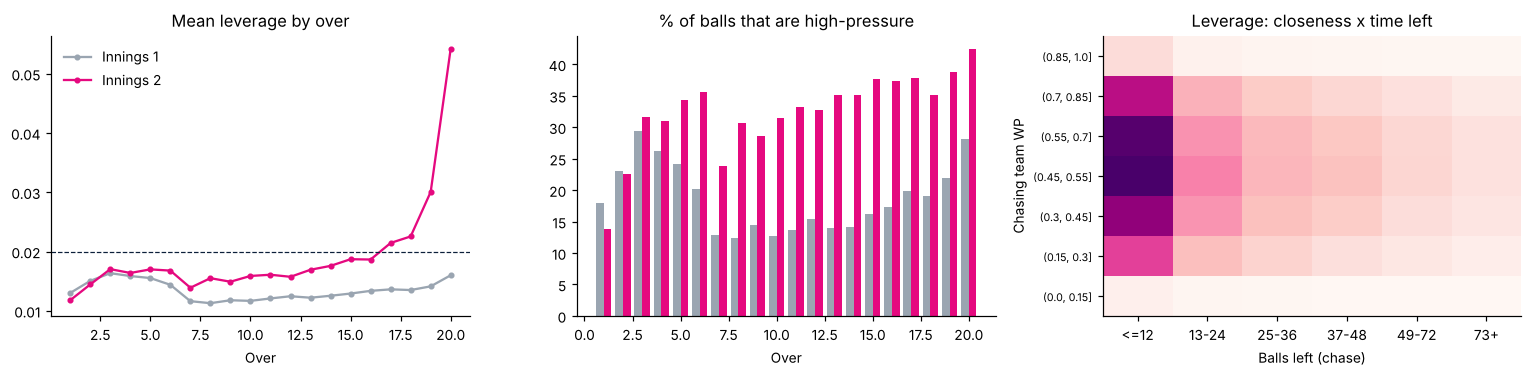

In [10]:
fig,ax=plt.subplots(1,3,figsize=(14,3.5))
x=b.groupby(['overid','innings']).LI.mean().unstack(); ax[0].plot(x.index,x[1],color=GREY,marker='o',ms=3,label='Innings 1'); ax[0].plot(x.index,x[2],color=PINK,marker='o',ms=3,label='Innings 2'); ax[0].axhline(THR,ls='--',color=NAVY,lw=.8); ax[0].legend(frameon=False); ax[0].set_title('Mean leverage by over'); ax[0].set_xlabel('Over')
y=b.groupby(['overid','innings']).HP.mean().unstack()*100; ax[1].bar(y.index-.2,y[1],.4,color=GREY); ax[1].bar(y.index+.2,y[2],.4,color=PINK); ax[1].set_title('% of balls that are high-pressure'); ax[1].set_xlabel('Over')
c=b[b.innings==2].copy(); c['bl']=pd.cut(c.balls_left,[0,12,24,36,48,72,120]); c['wpb']=pd.cut(c.wp0,[0,.15,.3,.45,.55,.7,.85,1])
hm=c.pivot_table(index='wpb',columns='bl',values='LI',aggfunc='mean'); im=ax[2].imshow(hm.values[::-1],cmap='RdPu',aspect='auto')
ax[2].set_xticks(range(6)); ax[2].set_xticklabels(['<=12','13-24','25-36','37-48','49-72','73+']); ax[2].set_yticks(range(7)); ax[2].set_yticklabels([str(i) for i in hm.index[::-1]],fontsize=7)
ax[2].set_xlabel('Balls left (chase)'); ax[2].set_ylabel('Chasing team WP'); ax[2].set_title('Leverage: closeness x time left'); plt.tight_layout(); plt.show()

In [11]:
# Does the pressure label separate tense situations from ordinary ones?
b['rrr']=np.where(b.innings==2,b.need/b.balls_left*6,np.nan); b['dot']=(b.tot==0)&b.legal; b['bnd']=b.is_four|b.is_six
tab=b.groupby('HP').agg(balls=('tot','size'),mean_leverage=('LI','mean'),abs_wp_from_50=('wp0',lambda x:(x-.5).abs().mean()),balls_left=('balls_left','mean'),wickets_lost=('wk_b','mean'),
    runs_per_over=('tot',lambda x:x.mean()*6),dot_rate=('dot','mean'),boundary_rate=('bnd','mean'),wicket_rate=('is_wicket','mean'),pct_chase=('innings',lambda x:(x==2).mean()),sd_of_swing=('v_bat','std'))
print(tab.T.round(3).rename(columns={False:'ordinary',True:'high-pressure'}))
# chase: share of HP by required rate band
rb=b[b.innings==2].groupby(pd.cut(b.rrr,[0,6,8,10,12,15,40])).agg(mean_LI=('LI','mean'),HP_share=('HP','mean'),balls=('LI','size')); print('\nChase pressure by required run rate:'); print(rb.round(3))
print('\nPressure by wickets lost:'); print(b.groupby('wk_b').agg(mean_LI=('LI','mean'),HP_share=('HP','mean')).round(3).T)

HP                ordinary  high-pressure
balls           131005.000      43669.000
mean_leverage        0.009          0.035
abs_wp_from_50       0.249          0.160
balls_left          63.048         60.475
wickets_lost         2.673          2.702
runs_per_over        8.518          8.748
dot_rate             0.339          0.325
boundary_rate        0.182          0.188
wicket_rate          0.053          0.055
pct_chase            0.436          0.612
sd_of_swing          0.021          0.055

Chase pressure by required run rate:
          mean_LI  HP_share  balls
rrr                               
(0, 6]      0.006     0.051  10030
(6, 8]      0.016     0.261  13865
(8, 10]     0.025     0.522  20988
(10, 12]    0.022     0.410  18186
(12, 15]    0.017     0.265  10936
(15, 40]    0.012     0.141   8600

Pressure by wickets lost:
wk_b          0      1      2      3      4      5      6      7      8      9
mean_LI   0.014  0.015  0.014  0.017  0.018  0.017  0.022  0.015  0.014 

## 6. Ball-level performance value
`v_bat` / `v_bowl` = win probability added over what an average ball would add in the same state (wides excluded for batters; byes/leg-byes not credited to batters; run-outs not credited to bowlers). The **efficiency** `v / LI` expresses the fraction of the stakes converted, so pressure and ordinary balls are comparable.

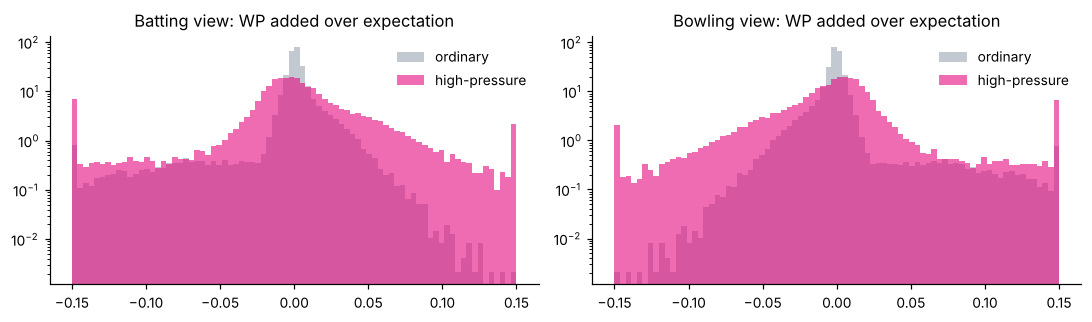

In [12]:
fig,ax=plt.subplots(1,2,figsize=(10,3))
for a,col,t in [(ax[0],'v_bat','Batting view'),(ax[1],'v_bowl','Bowling view')]:
    a.hist(b.loc[~b.HP,col].dropna().clip(-.15,.15),bins=80,alpha=.6,color=GREY,density=True,label='ordinary'); a.hist(b.loc[b.HP,col].dropna().clip(-.15,.15),bins=80,alpha=.6,color=PINK,density=True,label='high-pressure')
    a.set_title(f'{t}: WP added over expectation'); a.legend(frameon=False); a.set_yscale('log')
plt.tight_layout(); plt.show()

## 7. Player ratings: hierarchical ridge

In [13]:
names=pd.concat([b[['striker_id','striker_name']].set_axis(['pid','name'],axis=1),b[['bowler_id','bowler_name']].set_axis(['pid','name'],axis=1)]).drop_duplicates('pid').set_index('pid').name
def prep(view,hpcol='HP'):
    d=(b[b.bat_ok] if view=='bat' else b[b.bowl_ok]).copy()
    d['y']=(d.v_bat if view=='bat' else d.v_bowl)/d.LI.clip(lower=1e-3); d['y']=d.y.clip(-12,12)
    d['p']=d.striker_id if view=='bat' else d.bowler_id; d['o']=d.bowler_id if view=='bat' else d.striker_id; d['hp']=d[hpcol]
    return d.reset_index(drop=True)
def design(d,pids,oids,c):
    pi={p:i for i,p in enumerate(pids)}; oi={p:i for i,p in enumerate(oids)}; n=len(d); hp=d.hp.values.astype(float)
    P=sp.csr_matrix((np.ones(n),(np.arange(n),d.p.map(pi).values)),shape=(n,len(pids))); O=sp.csr_matrix((np.ones(n),(np.arange(n),d.o.map(oi).values)),shape=(n,len(oids)))
    return sp.hstack([P,sp.diags(hp*c)@P,O,sp.diags(hp*c)@O]).tocsr()
def fit(d,alpha=30,c=0.5,idx=None,sw=None):
    pids=np.sort(d.p.unique()); oids=np.sort(d.o.unique()); X=design(d,pids,oids,c)
    w=d.w.values*(1 if sw is None else sw); yy=d.y.values
    if idx is not None: X,yy,w=X[idx],yy[idx],w[idx]
    m=Ridge(alpha=alpha,solver='sparse_cg',tol=1e-6,max_iter=2000).fit(X,yy,sample_weight=w); k=len(pids)
    r=pd.DataFrame({'pid':pids,'usual':m.coef_[:k],'gam':m.coef_[k:2*k]*c}); r['hp']=r.usual+r.gam; return r.set_index('pid')
# --- tune penalty by match-grouped CV (error measured on HP balls)
t0=time.time(); tune=[]
for view in ['bat','bowl']:
    d=prep(view); pids=np.sort(d.p.unique()); oids=np.sort(d.o.unique())
    null=np.mean([np.average((d.y[(d.fold==f)&d.hp]-np.average(d.y[d.fold!=f],weights=d.w[d.fold!=f]))**2,weights=d.w[(d.fold==f)&d.hp]) for f in range(5)])
    for c in [1.0,0.5]:
        X=design(d,pids,oids,c)
        for a in [10,30,100]:
            e=[]
            for f in range(5):
                tr=np.where(d.fold!=f)[0]; te=np.where((d.fold==f)&d.hp)[0]
                m=Ridge(alpha=a,solver='sparse_cg',tol=1e-5,max_iter=1000).fit(X[tr],d.y.values[tr],sample_weight=d.w.values[tr]); e.append(np.average((d.y.values[te]-m.predict(X[te]))**2,weights=d.w.values[te]))
            tune.append((view,c,a,np.mean(e),null))
tune=pd.DataFrame(tune,columns=['view','shift_scale','alpha','cv_wmse','null_wmse']); tune['gain_vs_null_%']=(1-tune.cv_wmse/tune.null_wmse)*100
print(tune.round(5).to_string(index=False)); print(f'({time.time()-t0:.0f}s)  chosen: alpha=30, shift_scale=0.5')

view  shift_scale  alpha  cv_wmse  null_wmse  gain_vs_null_%
 bat          1.0     10  2.07749    2.07772         0.01109
 bat          1.0     30  2.07507    2.07772         0.12749
 bat          1.0    100  2.07583    2.07772         0.09076
 bat          0.5     10  2.07544    2.07772         0.10993
 bat          0.5     30  2.07489    2.07772         0.13637
 bat          0.5    100  2.07614    2.07772         0.07586
bowl          1.0     10  1.98199    1.98240         0.02064
bowl          1.0     30  1.97976    1.98240         0.13322
bowl          1.0    100  1.98052    1.98240         0.09465
bowl          0.5     10  1.98004    1.98240         0.11925
bowl          0.5     30  1.97958    1.98240         0.14215
bowl          0.5    100  1.98083    1.98240         0.07922
(2s)  chosen: alpha=30, shift_scale=0.5


In [14]:
def raw_stats(d,view):
    h=d[d.hp]; g=h.groupby('p'); u=d[~d.hp].groupby('p')
    cc=lambda x:(x.runs+np.where(x.extras_type.isin(['wide','Overstep','other']),x.extras1_runs,0)).sum()
    if view=='bat':
        s=pd.DataFrame({'hp_balls':g.size(),'hp_runs':g.runs.sum(),'hp_out':g.apply(lambda x:(x.bat_cls==6).sum()),'hp_matches':g.match_id.nunique()})
        s['hp_sr']=s.hp_runs/s.hp_balls*100; s['hp_ave']=s.hp_runs/s.hp_out.replace(0,np.nan); s['us_sr']=u.runs.sum()/u.size()*100
    else:
        s=pd.DataFrame({'hp_balls':g.legal.sum(),'hp_conc':g.apply(cc),'hp_wk':g.apply(lambda x:(x.bowl_cls==6).sum()),'hp_matches':g.match_id.nunique()})
        s['hp_econ']=s.hp_conc/s.hp_balls*6; s['hp_sr_b']=s.hp_balls/s.hp_wk.replace(0,np.nan); s['us_econ']=u.apply(cc)/u.legal.sum()*6
    return s
def consistency(d,view,k=6):
    col='v_bat' if view=='bat' else 'v_bowl'; thr=4 if view=='bat' else 6
    a=d[d.hp].groupby(['p','match_id','innings']).agg(n=(col,'size'),v=(col,'sum')).reset_index(); a=a[a.n>=thr]; a['pos']=(a.v>0).astype(float)
    g=a.groupby('p').agg(app=('pos','size'),pos=('pos','sum')); prior=a.pos.mean(); g['cons']=(g.pos+k*prior)/(g.app+k); return g
z=lambda x:(x-x.mean())/x.std()
ELIG={'bat':(100,15),'bowl':(120,15)}
def table(view,hpcol='HP',elig=None,alpha=30,c=0.5):
    d=prep(view,hpcol); r=fit(d,alpha,c).join(raw_stats(d,view)).join(consistency(d,view)); r['name']=names.reindex(r.index)
    mb,ma=elig or ELIG[view]; e=r[(r.hp_balls>=mb)&(r.app>=ma)].copy()
    e['z_level'],e['z_delta'],e['z_cons']=z(e.hp),z(e.gam),z(e.cons); e['score']=.55*e.z_level+.20*e.z_delta+.25*e.z_cons
    return e.sort_values('score',ascending=False),r
T={}; ALL={}
for v in ['bat','bowl']: T[v],ALL[v]=table(v); print(v,'players with any HP balls:',len(ALL[v]),'| eligible:',len(T[v]))

bat players with any HP balls: 645 | eligible: 99


bowl players with any HP balls: 468 | eligible: 68


## 8. Final top 10s

In [15]:
cb=['name','score','hp','gam','usual','cons','hp_balls','app','hp_sr','hp_ave','us_sr']; cw=['name','score','hp','gam','usual','cons','hp_balls','app','hp_econ','hp_wk','hp_sr_b','us_econ']
print('TOP 10 BATTERS UNDER PRESSURE'); display(T['bat'][cb].head(10).round(3).reset_index(drop=True).rename_axis('rank').rename(index=lambda i:i+1))
print('TOP 10 BOWLERS UNDER PRESSURE'); display(T['bowl'][cw].head(10).round(3).reset_index(drop=True).rename_axis('rank').rename(index=lambda i:i+1))
print('Columns: hp = pressure efficiency (usual+shift), gam = uplift vs usual, cons = shrunk share of pressure appearances with positive WP added, app = pressure innings/spells')

TOP 10 BATTERS UNDER PRESSURE


,name,score,hp,gam,usual,cons,hp_balls,app,hp_sr,hp_ave,us_sr
rank,,,,,,,,,,,
1,Abhishek Sharma,2.072,0.101,0.013,0.088,0.695,495.0,52.0,194.949,40.208,182.967
2,Jos Buttler,1.891,0.084,0.013,0.071,0.722,565.0,54.0,162.478,45.900,154.314
3,Suryakumar Yadav,1.819,0.103,0.011,0.091,0.634,645.0,56.0,164.961,42.560,166.530
4,Virat Kohli,1.800,0.099,0.012,0.087,0.641,548.0,46.0,146.350,72.909,145.386
5,Vaibhav Sooryavanshi,1.652,0.095,0.007,0.088,0.666,141.0,17.0,217.730,51.167,218.440
6,Phil Salt,1.636,0.091,0.010,0.080,0.650,363.0,36.0,168.044,43.571,171.637
7,Shreyas Iyer,1.615,0.087,0.014,0.073,0.627,432.0,36.0,159.259,45.867,152.402
8,Tim David,1.512,0.084,0.013,0.071,0.624,380.0,33.0,180.526,32.667,174.479
9,Sai Sudharsan,1.268,0.077,0.005,0.072,0.666,417.0,32.0,148.201,68.667,147.576


TOP 10 BOWLERS UNDER PRESSURE


,name,score,hp,gam,usual,cons,hp_balls,app,hp_econ,hp_wk,hp_sr_b,us_econ
rank,,,,,,,,,,,,
1,Rashid Khan,1.913,0.085,0.016,0.070,0.679,574.0,38.0,6.951,33.0,17.394,7.603
2,Sunil Narine,1.859,0.093,0.014,0.079,0.633,362.0,27.0,6.680,18.0,20.111,6.854
3,Varun Chakravarthy,1.854,0.100,0.014,0.086,0.603,473.0,32.0,8.106,32.0,14.781,7.994
4,Krunal Pandya,1.555,0.063,0.014,0.049,0.691,297.0,17.0,6.646,19.0,15.632,8.174
5,Lockie Ferguson,1.505,0.066,0.015,0.052,0.648,238.0,17.0,8.345,17.0,14.000,9.223
6,Wanindu Hasaranga,1.429,0.085,0.010,0.076,0.568,449.0,29.0,8.352,33.0,13.606,7.610
7,Jasprit Bumrah,1.359,0.069,0.011,0.058,0.617,445.0,36.0,7.362,18.0,24.722,7.229
8,Mitchell Santner,1.329,0.057,0.016,0.042,0.622,316.0,26.0,7.386,21.0,15.048,7.663
9,Kuldeep Yadav,1.285,0.065,0.013,0.052,0.597,405.0,29.0,7.437,26.0,15.577,8.169


Columns: hp = pressure efficiency (usual+shift), gam = uplift vs usual, cons = shrunk share of pressure appearances with positive WP added, app = pressure innings/spells


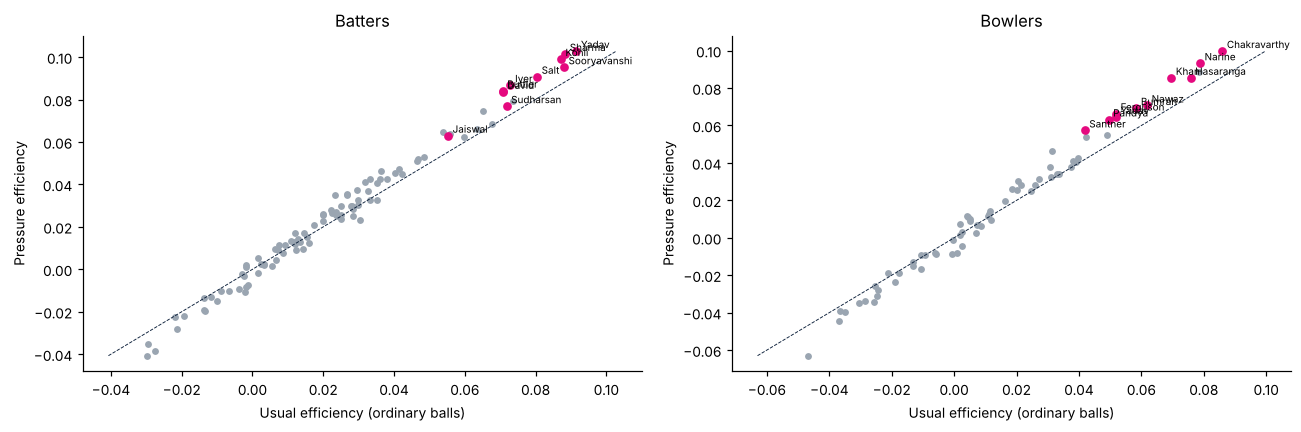

In [16]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
for a,(v,t) in zip(ax,[('bat','Batters'),('bowl','Bowlers')]):
    e=T[v]; top=e.head(10); a.scatter(e.usual,e.hp,s=12,color=GREY); a.scatter(top.usual,top.hp,s=22,color=PINK)
    for _,r in top.iterrows(): a.annotate(r['name'].split()[-1],(r.usual,r.hp),fontsize=6.5,xytext=(3,2),textcoords='offset points')
    lim=[e[['usual','hp']].min().min(),e[['usual','hp']].max().max()]; a.plot(lim,lim,'--',color=NAVY,lw=.6); a.set_xlabel('Usual efficiency (ordinary balls)'); a.set_ylabel('Pressure efficiency'); a.set_title(t)
plt.tight_layout(); plt.show()

## 9. Robustness

### 9a. Alternative definitions of pressure and component weights

In [17]:
b['HP_top10']=b.LI>=b.LI.quantile(.90)
b['HP_ex_pp']=(b.LI>=b.LI.quantile(.80))&(b.overid>6)
b['HP_inn']=b.li_pct>=.75 if 'li_pct' in b else (b.groupby('innings').LI.rank(pct=True)>=.75)
b['HP_rule']=b.wp0.between(.25,.75)&(b.balls_left<=48)&(((b.innings==2)&(b.need/b.balls_left*6>=8))|((b.innings==1)&((b.wk_b>=4)|(b.balls_left<=24))))
V={'main (top 25% LI)':'HP','top 10% LI':'HP_top10','top 20% excl. powerplay':'HP_ex_pp','within-innings top 25%':'HP_inn','rule-based close & late':'HP_rule'}
VT={}
for name,col in V.items():
    VT[name]={v:(T[v] if col=='HP' else table(v,col,elig=((60,8) if col=='HP_top10' else None))[0]) for v in ['bat','bowl']}
rows=[]
for name in V:
    r={'definition':name,'HP share':f'{b[V[name]].mean():.1%}'}
    for v in ['bat','bowl']: r[f'{v} top-10 overlap']=len(set(T[v].index[:10])&set(VT[name][v].index[:10]))
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print('\nComponent-weight sensitivity (overlap with main top 10):')
for w in [(1,0,0),(.4,.3,.3),(.7,.15,.15),(1/3,1/3,1/3)]:
    o=[]
    for v in ['bat','bowl']:
        e=T[v]; s=w[0]*e.z_level+w[1]*e.z_delta+w[2]*e.z_cons; o.append(len(set(e.index[:10])&set(s.sort_values(ascending=False).index[:10])))
    print(f'  weights level/uplift/consistency = {tuple(round(x,2) for x in w)}: batters {o[0]}/10, bowlers {o[1]}/10')

             definition HP share  bat top-10 overlap  bowl top-10 overlap
      main (top 25% LI)    25.0%                  10                   10
             top 10% LI    10.0%                   7                    6
top 20% excl. powerplay    13.9%                   6                    6
 within-innings top 25%    25.0%                   9                    8
rule-based close & late    13.3%                   4                    6

Component-weight sensitivity (overlap with main top 10):
  weights level/uplift/consistency = (1, 0, 0): batters 9/10, bowlers 9/10
  weights level/uplift/consistency = (0.4, 0.3, 0.3): batters 10/10, bowlers 9/10
  weights level/uplift/consistency = (0.7, 0.15, 0.15): batters 9/10, bowlers 9/10
  weights level/uplift/consistency = (0.33, 0.33, 0.33): batters 9/10, bowlers 9/10


### 9b. Bootstrap over matches (Poisson weights) and split-half reliability

20 bootstrap reps in 2s


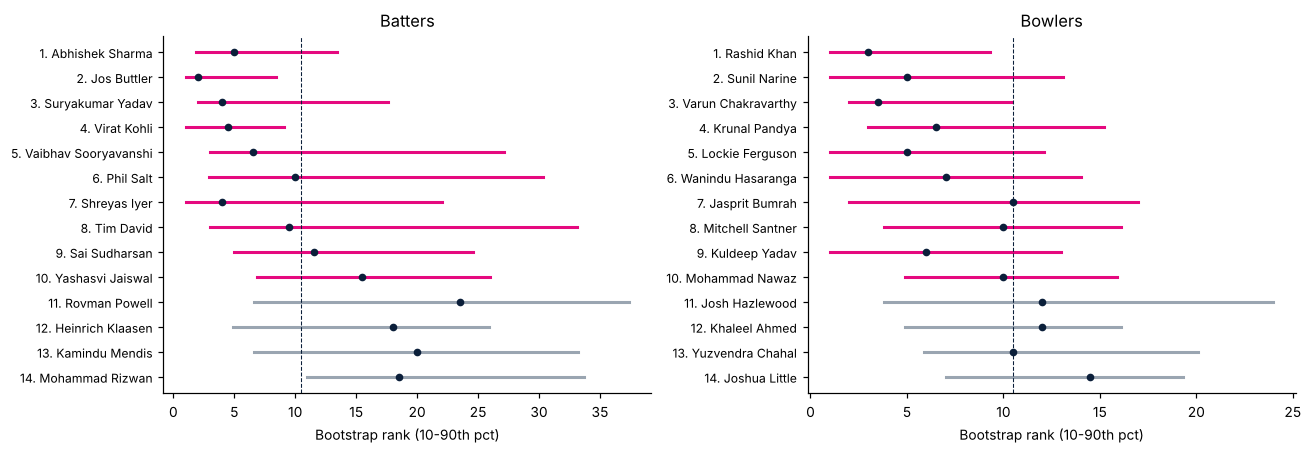

                Batters                        Bowlers           
                   name top10_prob                name top10_prob
0       Abhishek Sharma       0.85         Rashid Khan       0.90
1           Jos Buttler       0.90        Sunil Narine       0.85
2      Suryakumar Yadav       0.75  Varun Chakravarthy       0.90
3           Virat Kohli       0.95       Krunal Pandya       0.70
4  Vaibhav Sooryavanshi       0.60     Lockie Ferguson       0.85
5             Phil Salt       0.55   Wanindu Hasaranga       0.80
6          Shreyas Iyer       0.80      Jasprit Bumrah       0.50
7             Tim David       0.50    Mitchell Santner       0.50
8         Sai Sudharsan       0.50       Kuldeep Yadav       0.75
9      Yashasvi Jaiswal       0.30      Mohammad Nawaz       0.55


In [18]:
REPS=20; rng=np.random.RandomState(7); rk={'bat':{},'bowl':{}}; D={v:prep(v) for v in ['bat','bowl']}; mids_all=b.match_id.unique(); t0=time.time()
for rep in range(REPS):
    mult=pd.Series(rng.poisson(1,len(mids_all)),index=mids_all)
    for v in ['bat','bowl']:
        r=fit(D[v],sw=D[v].match_id.map(mult).values.astype(float)); e=T[v][['cons']].join(r[['hp','gam']])
        s=.55*z(e.hp)+.2*z(e.gam)+.25*z(e.cons); rr=s.rank(ascending=False)
        for pid,val in rr.items(): rk[v].setdefault(pid,[]).append(val)
print(f'{REPS} bootstrap reps in {time.time()-t0:.0f}s')
fig,ax=plt.subplots(1,2,figsize=(12,4.2))
for a,(v,t) in zip(ax,[('bat','Batters'),('bowl','Bowlers')]):
    e=T[v].head(14)
    for i,pid in enumerate(e.index):
        lo,med,hi=np.percentile(rk[v][pid],[10,50,90]); a.plot([lo,hi],[i,i],color=PINK if i<10 else GREY,lw=2); a.plot(med,i,'o',color=NAVY,ms=4)
    a.set_yticks(range(14)); a.set_yticklabels([f'{i+1}. {n}' for i,n in enumerate(e.name)],fontsize=8); a.invert_yaxis(); a.axvline(10.5,ls='--',color=NAVY,lw=.7); a.set_xlabel('Bootstrap rank (10-90th pct)'); a.set_title(t)
plt.tight_layout(); plt.show()
for v in ['bat','bowl']: T[v]['top10_prob']=[np.mean(np.array(rk[v][p])<=10) for p in T[v].index]
print(pd.concat([T['bat'].head(10)[['name','top10_prob']].reset_index(drop=True),T['bowl'].head(10)[['name','top10_prob']].reset_index(drop=True)],axis=1,keys=['Batters','Bowlers']).round(2))

In [19]:
# split-half reliability of the pressure-level estimate
rng=np.random.RandomState(3); out={}
for v in ['bat','bowl']:
    rr=[]
    for s in range(4):
        half=pd.Series(rng.rand(len(mids_all))<.5,index=mids_all); h=D[v].match_id.map(half).values
        r1=fit(D[v],idx=np.where(h)[0]); r2=fit(D[v],idx=np.where(~h)[0]); j=r1.join(r2,lsuffix='1',rsuffix='2',how='inner'); j=j[j.index.isin(T[v].index)]
        rr.append((spearmanr(j.hp1,j.hp2)[0],pearsonr(j.hp1,j.hp2)[0]))
    out[v]=np.mean(rr,0); r=out[v][1]; print(f'{v}: split-half Spearman {out[v][0]:.2f}, Pearson {r:.2f}  -> full-sample (Spearman-Brown) ~ {2*r/(1+r):.2f}')

bat: split-half Spearman 0.20, Pearson 0.23  -> full-sample (Spearman-Brown) ~ 0.37


bowl: split-half Spearman 0.41, Pearson 0.40  -> full-sample (Spearman-Brown) ~ 0.57


## 10. Extra analysis

### 10a. What the model adds over naive pressure stats

In [20]:
# Naive 'death overs' (16-20) metric vs our model, for eligible batters
nv=b[(b.overid>=16)&b.bat_ok&b.legal].groupby('striker_id').agg(balls=('runs','size'),runs=('runs','sum'),outs=('bat_cls',lambda x:(x==6).sum()))
nv['death_sr']=nv.runs/nv.balls*100; e=T['bat'].join(nv[['balls','death_sr']].rename(columns={'balls':'death_balls'}))
e=e[e.death_balls>=60]; print(f'Eligible batters with 60+ death-over balls: {len(e)}')
print('Spearman(model pressure score, death-over strike rate): %.2f'%spearmanr(e.score,e.death_sr)[0])
print('Spearman(model pressure score, HP strike rate):        %.2f'%spearmanr(e.score,e.hp_sr)[0])
print('Spearman(model pressure score, usual strike rate):     %.2f'%spearmanr(e.score,e.us_sr)[0])
# Naive ranking: HP strike rate among eligible batters, how different is the top 10?
nvt=T['bat'].sort_values('hp_sr',ascending=False).head(10)
print('\nTop-10 by raw HP strike rate:',', '.join(nvt.name)); print('Overlap with model top 10:',len(set(nvt.index)&set(T['bat'].index[:10])),'/10')
nvb=T['bowl'].sort_values('hp_econ').head(10); print('\nTop-10 bowlers by raw HP economy:',', '.join(nvb.name)); print('Overlap with model top 10:',len(set(nvb.index)&set(T['bowl'].index[:10])),'/10')

Eligible batters with 60+ death-over balls: 74
Spearman(model pressure score, death-over strike rate): 0.30
Spearman(model pressure score, HP strike rate):        0.48
Spearman(model pressure score, usual strike rate):     0.19

Top-10 by raw HP strike rate: Vaibhav Sooryavanshi, Abhishek Sharma, Dewald Brevis, Prabhsimran Singh, Tim David, Heinrich Klaasen, Mohammad Nabi, Travis Head, Andre Russell, Dinesh Karthik
Overlap with model top 10: 3 /10

Top-10 bowlers by raw HP economy: Krunal Pandya, Sunil Narine, Abrar Ahmed, Rashid Khan, Taskin Ahmed, Joshua Little, Maheesh Theekshana, Mohammad Nawaz, Jasprit Bumrah, Mitchell Santner
Overlap with model top 10: 6 /10


### 10b. Does the pressure shift ('clutch') exist? Is it stable?

Mean uplift (gam) among eligible: batters 0.0022 | bowlers 0.0023  (level spread, SD of hp: 0.033 | 0.037)


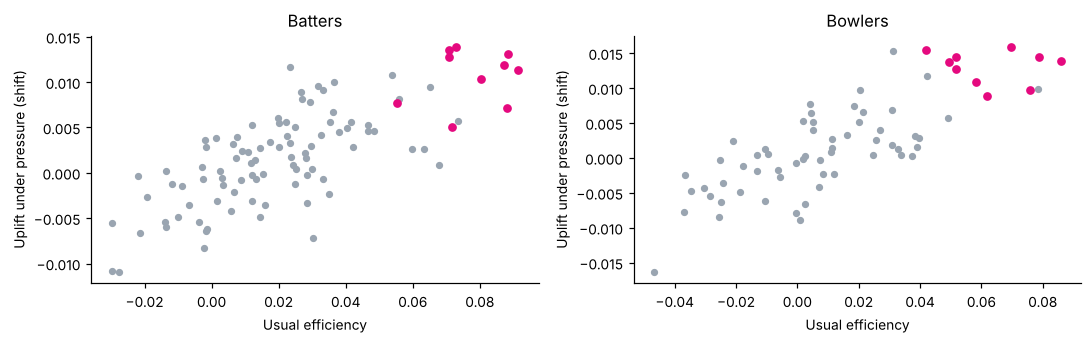

Correlation usual vs uplift: batters 0.75 | bowlers 0.80

In [21]:
print('Mean uplift (gam) among eligible: batters %.4f | bowlers %.4f  (level spread, SD of hp: %.3f | %.3f)'%(T['bat'].gam.mean(),T['bowl'].gam.mean(),T['bat'].hp.std(),T['bowl'].hp.std()))
fig,ax=plt.subplots(1,2,figsize=(10,3.2))
for a,(v,t) in zip(ax,[('bat','Batters'),('bowl','Bowlers')]):
    e=T[v]; a.scatter(e.usual,e.gam,s=14,color=GREY); a.scatter(e.head(10).usual,e.head(10).gam,s=22,color=PINK); a.set_xlabel('Usual efficiency'); a.set_ylabel('Uplift under pressure (shift)'); a.set_title(t)
plt.tight_layout(); plt.show()
print('Correlation usual vs uplift: batters %.2f | bowlers %.2f'%(T['bat'][['usual','gam']].corr().iloc[0,1],T['bowl'][['usual','gam']].corr().iloc[0,1]))

### 10c. IPL vs T20I composition of the top 10

In [22]:
for v,col in [('bat','striker_id'),('bowl','bowler_id')]:
    comp=b[b.HP].groupby([col,'is_ipl']).size().unstack(fill_value=0); comp.columns=['T20I_HP_balls','IPL_HP_balls']
    e=T[v].head(10)[['name']].join(comp); e['IPL_share']=(e.IPL_HP_balls/(e.IPL_HP_balls+e.T20I_HP_balls)).round(2); print(('Batters' if v=='bat' else 'Bowlers')); print(e.reset_index(drop=True).to_string())

Batters
                   name  T20I_HP_balls  IPL_HP_balls  IPL_share
0       Abhishek Sharma            188           337       0.64
1           Jos Buttler            198           384       0.66
2      Suryakumar Yadav            327           338       0.51
3           Virat Kohli            115           460       0.80
4  Vaibhav Sooryavanshi             30           122       0.80
5             Phil Salt            236           139       0.37
6          Shreyas Iyer            130           325       0.71
7             Tim David            205           198       0.49
8         Sai Sudharsan              0           430       1.00
9      Yashasvi Jaiswal             76           381       0.83
Bowlers
                 name  T20I_HP_balls  IPL_HP_balls  IPL_share
0         Rashid Khan            206           372       0.64
1        Sunil Narine              0           366       1.00
2  Varun Chakravarthy            168           313       0.65
3       Krunal Pandya           

### 10d. Phase profile of the top 10 batters and bowlers (high-pressure balls)

In [23]:
b['phase']=pd.cut(b.overid,[0,6,15,20],labels=['PP','Middle','Death'])
hb=b[b.HP&b.bat_ok]; tb=hb[hb.striker_id.isin(T['bat'].index[:10])]; print('Share of top-10 batters\' HP balls by phase:'); print(tb.groupby(['striker_name','phase']).size().unstack(fill_value=0).pipe(lambda x:x.div(x.sum(1),axis=0)).round(2).loc[T['bat'].head(10).name])
hw=b[b.HP&b.bowl_ok&b.legal]; tw=hw[hw.bowler_id.isin(T['bowl'].index[:10])]; print('\nShare of top-10 bowlers\' HP balls by phase:'); print(tw.groupby(['bowler_name','phase']).size().unstack(fill_value=0).pipe(lambda x:x.div(x.sum(1),axis=0)).round(2).loc[T['bowl'].head(10).name])

Share of top-10 batters' HP balls by phase:
phase                   PP  Middle  Death
striker_name                             
Abhishek Sharma       0.75    0.25   0.01
Jos Buttler           0.54    0.37   0.09
Suryakumar Yadav      0.24    0.62   0.14
Virat Kohli           0.52    0.40   0.08
Vaibhav Sooryavanshi  0.75    0.23   0.02
Phil Salt             0.69    0.25   0.05
Shreyas Iyer          0.29    0.54   0.17
Tim David             0.06    0.45   0.49
Sai Sudharsan         0.47    0.47   0.06
Yashasvi Jaiswal      0.65    0.33   0.02

Share of top-10 bowlers' HP balls by phase:
phase                 PP  Middle  Death
bowler_name                            
Rashid Khan         0.14    0.65   0.21
Sunil Narine        0.15    0.68   0.18
Varun Chakravarthy  0.18    0.66   0.16
Krunal Pandya       0.15    0.79   0.05
Lockie Ferguson     0.36    0.34   0.30
Wanindu Hasaranga   0.06    0.76   0.18
Jasprit Bumrah      0.46    0.20   0.35
Mitchell Santner    0.22    0.63   0.15
Kuldeep

## 11. Export

In [24]:
for v in ['bat','bowl']:
    e=T[v].copy(); e.insert(0,'rank',range(1,len(e)+1)); e.to_csv(OUT_DIR+f'{v}_ratings_all_eligible.csv')
print('Saved CSVs to',OUT_DIR)
print('\nFINAL SUBMISSION'); print('Batters :',' > '.join(T['bat'].name.head(10))); print('Bowlers :',' > '.join(T['bowl'].name.head(10)))

Saved CSVs to /mnt/user-data/outputs/

FINAL SUBMISSION
Batters : Abhishek Sharma > Jos Buttler > Suryakumar Yadav > Virat Kohli > Vaibhav Sooryavanshi > Phil Salt > Shreyas Iyer > Tim David > Sai Sudharsan > Yashasvi Jaiswal
Bowlers : Rashid Khan > Sunil Narine > Varun Chakravarthy > Krunal Pandya > Lockie Ferguson > Wanindu Hasaranga > Jasprit Bumrah > Mitchell Santner > Kuldeep Yadav > Mohammad Nawaz


## 12. Export the dashboard data
Writes `dashboard_data/{league_stats,outcome_probs,wp_grid,players,matches}.json` straight from the in-memory objects (`b`, `T`, `ALL`, `VT`, `models`, `PB/PW`, bootstrap and split-half results).
`wp_grid` is the mean of the five cross-fit models evaluated on a fixed grid; `matches.json` holds the ball-by-ball WP/leverage trace of the 30 matches with the highest mean chase leverage.

In [ ]:
# ===== 12. Export the dashboard JSON files from the in-memory pipeline (no hand-made files) =====
import json, os
OUTJ = OUT_DIR + 'dashboard_data/'; os.makedirs(OUTJ, exist_ok=True)
dump = lambda obj, name: json.dump(obj, open(OUTJ + name, 'w'), separators=(',', ':'), allow_nan=False)
r4 = lambda x, n=4: None if pd.isna(x) else round(float(x), n)
tname = {**raw_m.set_index('home_team_id').home_team.to_dict(), **raw_m.set_index('away_team_id').away_team.to_dict()}

# --- 12a league_stats.json : every aggregate the dashboard shows on the "Pressure" page
cal = b.groupby(pd.cut(b.wp0, np.linspace(0, 1, 11))).agg(pred=('wp0', 'mean'), obs=('y', 'mean'), n=('y', 'size'))
bandsR = b[b.innings == 2].groupby(pd.cut(b.rrr, [0, 6, 8, 10, 12, 15, 40]))
hm = b[b.innings == 2].assign(bl=lambda c: pd.cut(c.balls_left, [0, 12, 24, 36, 48, 72, 120]), wpb=lambda c: pd.cut(c.wp0, [0, .15, .3, .45, .55, .7, .85, 1])
        ).pivot_table(index='wpb', columns='bl', values='LI', aggfunc='mean')
lv = b.groupby(['innings', 'overid']); tabHP = b.groupby('HP')
col = lambda f: {'ordinary': r4(f(tabHP.get_group(False))), 'high_pressure': r4(f(tabHP.get_group(True)))}
league = {
 'counts': {'matches': int(b.match_id.nunique()), 'ipl': int(b[b.is_ipl == 1].match_id.nunique()), 't20i': int(b[b.is_ipl == 0].match_id.nunique()), 'balls': int(len(b))},
 'model': {'brier_inn1': r4(brier_score_loss(b[b.innings == 1].y, b[b.innings == 1].wp0)), 'brier_inn2': r4(brier_score_loss(b[b.innings == 2].y, b[b.innings == 2].wp0)),
           'auc_inn1': r4(roc_auc_score(b[b.innings == 1].y, b[b.innings == 1].wp0), 2), 'auc_inn2': r4(roc_auc_score(b[b.innings == 2].y, b[b.innings == 2].wp0), 3)},
 'leverage_by_over': {f'inn{i}': [r4(v) for v in b[b.innings == i].groupby('overid').LI.mean()] for i in (1, 2)},
 'hp_share_by_over': {f'inn{i}': [r4(v, 3) for v in b[b.innings == i].groupby('overid').HP.mean()] for i in (1, 2)},
 'by_required_rate': [{'band': str(k), 'li': r4(g.LI.mean()), 'hp': r4(g.HP.mean(), 3), 'n': int(len(g))} for k, g in bandsR],
 'by_wickets_lost': [{'wk': int(k), 'li': r4(g.LI.mean()), 'hp': r4(g.HP.mean(), 3)} for k, g in b.groupby('wk_b')],
 'heatmap_chase': {'rows_wp': [str(i) for i in hm.index], 'cols_balls_left': [str(i) for i in hm.columns], 'values': [[r4(v) for v in row] for row in hm.values]},
 'hp_vs_ordinary': {'LI': col(lambda g: g.LI.mean()), 'absdev': col(lambda g: (g.wp0 - .5).abs().mean()), 'balls_left': col(lambda g: g.balls_left.mean()),
     'wk_lost': col(lambda g: g.wk_b.mean()), 'rpo': col(lambda g: g.tot.mean() * 6), 'dot': col(lambda g: ((g.tot == 0) & g.legal).mean()),
     'bnd': col(lambda g: (g.is_four | g.is_six).mean()), 'wkt': col(lambda g: g.is_wicket.mean()), 'share2': col(lambda g: (g.innings == 2).mean()), 'sd_dwp': col(lambda g: g.v_bat.std())},
 'calibration': [{'pred': r4(r.pred, 3), 'obs': r4(r.obs, 3), 'n': int(r.n)} for r in cal.itertuples()],
 'robustness': {'overlap_with_main_top10': {k: {v: int(len(set(T[v].index[:10]) & set(VT[nm][v].index[:10]))) for v in ('bat', 'bowl')}
                    for k, nm in [('top10', 'top 10% LI'), ('ex_powerplay', 'top 20% excl. powerplay'), ('within_innings', 'within-innings top 25%'), ('rule_based', 'rule-based close & late')]},
                'split_half': {v: r4(out[v][1], 2) for v in ('bat', 'bowl')}}}
dump(league, 'league_stats.json')

# --- 12b outcome_probs.json : league outcome probabilities per (competition, over) + threshold + leverage percentiles
PBt, PWt = probs(b.bat_cls, b.bat_ok, 7), probs(b.bowl_cls, b.bowl_ok, 8)
dump({'outcomes_bowl': ['0', '1', '2', '3', '4', '6', 'W', 'Wd'], 'outcomes_bat': ['0', '1', '2', '3', '4', '6', 'W'], 'key': '{is_ipl}_{over 1..20}',
      'probs': {f'{k // 100}_{k % 100}': {'bat': [r4(x) for x in PBt.loc[k]], 'bowl': [r4(x) for x in PWt.loc[k]]} for k in PBt.index},
      'hp_threshold': r4(THR), 'li_cap_p99': r4(CAP), 'li_percentiles': [r4(x) for x in np.quantile(b.LI, np.linspace(0, 1, 101))]}, 'outcome_probs.json')

# --- 12c wp_grid.json : the WP model evaluated on a regular grid (mean of the 5 cross-fit models)
AX = {'wk': list(range(10)), 'balls_left': [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 18, 21, 24, 30, 36, 42, 48, 60, 72, 84, 96, 108, 120],
      'need': [1, 2, 3, 4, 6, 8, 10, 12, 15, 18, 21, 24, 28, 32, 36, 40, 45, 50, 55, 60, 70, 80, 90, 100, 115, 130, 150, 175, 200, 230, 260],
      'runs': [0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 175, 190, 205, 220, 240, 260]}
def grid(inn, ipl):
    last = AX['runs'] if inn == 1 else AX['need']; W, BL, X = np.meshgrid(AX['wk'], AX['balls_left'], last, indexing='ij')
    F = np.c_[X.ravel(), BL.ravel(), W.ravel(), np.full(W.size, ipl)]
    p = np.mean([models[(f, inn)].predict_proba(F)[:, 1] for f in range(5)], axis=0)
    return np.round(p.reshape(W.shape), 3).tolist()
dump({'axes': AX, 'note': 'index [wk][balls_left][need|runs]; innings1 axis=runs scored, innings2 axis=runs needed. Terminal rules: chase won if runs>=target, lost if balls_left<=0 or wk>=10',
      'grids': {f'i{i}_{n}': grid(i, f) for i in (1, 2) for n, f in (('t20i', 0), ('ipl', 1))}}, 'wp_grid.json')

# --- 12d players.json : one record per player with >=30 HP balls, incl. the alternative-definition variants and phase / team profile
DEFS = {'main': 'HP', 'top10': 'HP_top10', 'ex_powerplay': 'HP_ex_pp', 'within_innings': 'HP_inn', 'rule_based': 'HP_rule'}
VARS = {k: {v: (ALL[v] if c == 'HP' else table(v, c)[1]) for v in ('bat', 'bowl')} for k, c in DEFS.items()}
b['phase'] = pd.cut(b.overid, [0, 6, 15, 20], labels=['pp', 'mid', 'death'])
last_ipl = b[b.is_ipl == 1].sort_values('match_id')
def profile(v):
    pc, tc, ok = ('striker_id', 'batting_team_id', 'bat_ok') if v == 'bat' else ('bowler_id', 'bowling_team_id', 'bowl_ok')
    h = b[b.HP & b[ok]]; ph = h.groupby([pc, 'phase']).size().unstack(fill_value=0); ph = ph.div(ph.sum(1), axis=0)
    ip = h.groupby(pc).is_ipl.mean(); tm = last_ipl.groupby(pc)[tc].last().map(tname)
    return ph, ip, tm
def records(v):
    ph, ip, tm = profile(v); R = ALL[v]; R = R[R.hp_balls >= 30]; out = []
    for pid, r in R.sort_values('hp', ascending=False).iterrows():
        rec = {'id': int(pid), 'name': r['name'], 'hb': int(r.hp_balls), 'app': 0 if pd.isna(r.app) else int(r.app), 'hp': r4(r.hp), 'gam': r4(r.gam), 'usual': r4(r.usual), 'cons': r4(r.cons, 3)}
        if v == 'bat':
            h = b[(b.striker_id == pid) & b.HP & b.bat_ok & b.legal]
            rec |= {'hp_sr': r4(r.hp_sr, 1), 'hp_ave': r4(r.hp_ave, 1), 'us_sr': r4(r.us_sr, 1), 'hp_dot': r4((h.runs == 0).mean(), 3), 'hp_bnd': r4((h.is_four | h.is_six).mean(), 3)}
        else:
            rec |= {'hp_econ': r4(r.hp_econ, 2), 'hp_wk': int(r.hp_wk), 'hp_balls_per_wkt': r4(r.hp_sr_b, 1), 'us_econ': r4(r.us_econ, 2)}
        rec['variants'] = {k: [r4(V.loc[pid, 'hp']), r4(V.loc[pid, 'gam']), r4(V.loc[pid, 'cons'], 3), int(V.loc[pid, 'hp_balls']), 0 if pd.isna(V.loc[pid, 'app']) else int(V.loc[pid, 'app'])]
                           for k, V in ((k, VARS[k][v]) for k in DEFS) if pid in V.index and V.loc[pid, 'hp_balls'] >= 1}
        rec['phase'] = {k: r4(ph.loc[pid, k], 2) if pid in ph.index else 0.0 for k in ('pp', 'mid', 'death')}
        rec['ipl_share'] = r4(ip.get(pid, 0.0), 2); rec['ipl_team'] = tm.get(pid, None)
        out.append(rec)
    return out
dump({'definitions': {'main': 'top 25% leverage (submission)', 'top10': 'top 10% leverage', 'ex_powerplay': 'top 20% leverage, overs 7-20 only', 'within_innings': 'top 25% leverage within each innings',
      'rule_based': 'close (WP 25-75%) & late with required rate >= 8 or collapse'}, 'eligibility_default': {'bat': {'min_hp_balls': 100, 'min_app': 15}, 'bowl': {'min_hp_balls': 120, 'min_app': 15}},
      'weights_default': {'level': 0.55, 'uplift': 0.2, 'consistency': 0.25}, 'final_top10': {v: list(T[v].name.head(10)) for v in ('bat', 'bowl')},
      'bat': records('bat'), 'bowl': records('bowl')}, 'players.json')

# --- 12e matches.json : ball-by-ball WP / leverage traces for the 30 most tense matches (mean chase leverage) shown in the "Match explorer"
tense = b[b.innings == 2].groupby('match_id').LI.mean().nlargest(30).index
mi = mm.set_index('match_id'); pid_seen = set(); M = []
for mid in tense:
    g = b[b.match_id == mid]; m = mi.loc[mid]; tm_ = lambda i: tname[g[g.innings == i].batting_team_id.iloc[0]]
    ser = lambda i: [[int(r.overid), int(r.over_ball_num), int(r.runs_b), int(r.wk_b), r4(r.wp0, 3), r4(r.LI), int(r.tot), int(r.is_wicket), int(r.striker_id), int(r.bowler_id)] for r in g[g.innings == i].itertuples()]
    s1, s2 = ser(1), ser(2); pid_seen |= {x[8] for x in s1 + s2} | {x[9] for x in s1 + s2}
    M.append({'id': int(mid), 'date': pd.to_datetime(m.match_date, dayfirst=True).strftime('%Y-%m-%d'), 'home': m.home_team, 'away': m.away_team, 'bat1': tm_(1), 'bat2': tm_(2), 'result': m.result,
              'target': int(g.target.iloc[0]), 'ipl': int(m.is_ipl), 'series_cols': ['over', 'ball', 'runs_before', 'wk_before', 'wp_batting_team', 'leverage', 'runs_ball', 'wicket', 'striker_id', 'bowler_id'], 'i1': s1, 'i2': s2})
dump({'matches': M, 'names': {str(p): names[p] for p in pid_seen if p in names.index}}, 'matches.json')
print('Wrote:', ', '.join(f'{f} ({os.path.getsize(OUTJ + f) / 1e3:.0f} KB)' for f in sorted(os.listdir(OUTJ))))


## 13. Audit cells (re-check the report's claims against this notebook's own objects)

In [ ]:
# 13a. Super-over / tie audit: matches whose recorded result mentions a tie or super over but were NOT filtered by the regex in Section 2
sus=raw_m[(ipl|t20i)&raw_m.result.fillna('').str.contains('super over|tie',case=False)]
print('matches mentioning tie/super over among IPL + full-member T20I:',len(sus),'| of which kept in the analysis sample:',sus.match_id.isin(mm.match_id).sum())
print(sus[['match_id','match_date','home_team','away_team','result']].to_string(index=False))

# 13b. Composite score recomputed independently from the rating table
for v in ['bat','bowl']:
    e=T[v]; s=.55*z(e.hp)+.20*z(e.gam)+.25*z(e.cons)
    print(v,'score reproduces:',np.allclose(s,e.score),'| eligible:',len(e),'| hp=usual+gam:',np.allclose(e.hp,e.usual+e.gam))

# 13c. Distance between rank 10 and rank 11 (how firm is the cut-off?)
for v in ['bat','bowl']:
    e=T[v]; print(v,'rank10 %s %.4f | rank11 %s %.4f | gap %.4f'%(e.name.iloc[9],e.score.iloc[9],e.name.iloc[10],e.score.iloc[10],e.score.iloc[9]-e.score.iloc[10]))

# 13d. Bootstrap precision: with REPS resamples the top-10 probability has standard error ~ sqrt(p(1-p)/REPS)
print('Bootstrap reps used:',REPS,'-> worst-case s.e. of top10_prob = %.3f (use REPS>=200 for the final submission)'%(0.5/np.sqrt(REPS)))